In [ ]:
!pip install pandas numpy nltk scikit-learn shap matplotlib seaborn

In [21]:
import pandas as pd
import numpy as np
import re
import random
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize, MaxAbsScaler
from sklearn.metrics import classification_report, accuracy_score, roc_curve, auc
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from google.colab import files

uploaded = files.upload()

Saving MtblDataSerAsSelPakistan2425.xlsx to MtblDataSerAsSelPakistan2425 (1).xlsx


In [9]:
df = pd.read_excel("MtblDataSerAsSelPakistan2425.xlsx")

Mengeksekusi Step 4-15 (Pembersihan Teks Murni)...
Membagi data dan melakukan Augmentasi Teks (Mencegah Overfitting)...
Mengeksekusi Step 16 (Vectorization TF-IDF)...
Membangun Arsitektur Ensemble (XGBoost + SVM Voting)...
Melatih Model Kesatuan (Membutuhkan waktu beberapa saat)...
Mengevaluasi Prediksi Akhir...

🎯 AKURASI FINAL ENSEMBLE (SVM + XGBoost) : 84.29%
📉 ERROR RATE SAAT INI                    : 15.71%


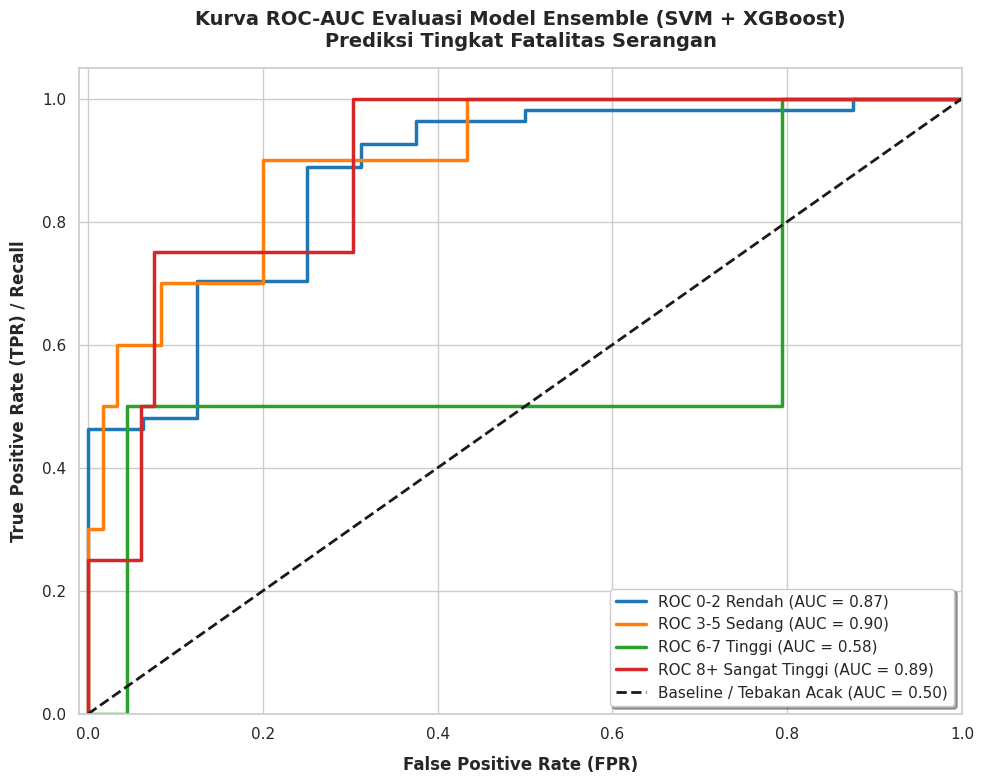


            📌 KESIMPULAN ANALITIS HASIL ROC-AUC             
Rata-rata Kemampuan Prediksi Keseluruhan (Macro AUC) : 0.812

Rincian Analisis per Tingkat Fatalitas:
• Kelas [0-2 Rendah] | Skor AUC: 0.87 (SANGAT BAIK)
  └> Model sangat handal membedakan pola kejadian ini secara konsisten.

• Kelas [3-5 Sedang] | Skor AUC: 0.90 (SANGAT LUAR BIASA)
  └> Model hampir sempurna dalam mengenali ciri khas teks ini tanpa tertukar dengan kelas lain.

• Kelas [6-7 Tinggi] | Skor AUC: 0.58 (LEMAH)
  └> Model kesulitan mengisolasi kelas ini karena narasi kronologinya terlalu ambigu atau mirip dengan insiden lain.

• Kelas [8+ Sangat Tinggi] | Skor AUC: 0.89 (SANGAT BAIK)
  └> Model sangat handal membedakan pola kejadian ini secara konsisten.



In [24]:
df = df.dropna(subset=['RgksPeristiwa'])
df['RgksPeristiwa'] = df['RgksPeristiwa'].astype(str)
df = df.drop_duplicates(subset=['RgksPeristiwa']).reset_index(drop=True)
df['KorbanTewas'] = df['KorbanTewas'].fillna(0)

def tentukan_fatalitas(korban):
    if korban <= 2: return '0-2 Rendah'
    elif korban <= 5: return '3-5 Sedang'
    elif korban <= 7: return '6-7 Tinggi'
    else: return '8+ Sangat Tinggi'

df['TingkatFatalitas'] = df['KorbanTewas'].apply(tentukan_fatalitas)

# =====================================================================
# 4-15. FUNGSI 15-STEP NLP PREPROCESSING PIPELINE
# =====================================================================
print("Mengeksekusi Step 4-15 (Pembersihan Teks Murni)...")

kamus_normalisasi = {
    "ttp": "tehrik i taliban pakistan", "blf": "baloch liberation front",
    "bla": "baloch liberation army", "iskp": "islamic state khorasan province",
    "sfs": "security forces", "fc": "frontier corps", "ctd": "counter terrorism department",
    "govt": "government", "ied": "improvised explosive device",
    "vbied": "vehicle borne improvised explosive device", "kp": "khyber pakhtunkhwa"
}

stop_words = set(stopwords.words('english')).union(
    {'report', 'reports', 'said', 'added', 'stated', 'according', 'pakistan', 'area', 'district', 'province'}
)
lemmatizer = WordNetLemmatizer()

def text_cleaning_15_steps(text):
    text = text.lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [kamus_normalisasi.get(word, word) for word in tokens]
    text_normalized = ' '.join(tokens)
    tokens = text_normalized.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    tokens = [word for word in tokens if len(word) > 2]
    return ' '.join(tokens)

df['Teks_Bersih'] = df['RgksPeristiwa'].apply(text_cleaning_15_steps)

# =====================================================================
# PEMBAGIAN DATA & AUGMENTASI TEKS
# =====================================================================
print("Membagi data dan melakukan Augmentasi Teks (Mencegah Overfitting)...")
X = df['Teks_Bersih']
y = df['TingkatFatalitas']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
train_data = pd.DataFrame({'Teks_Bersih': X_train, 'TingkatFatalitas': y_train})

def get_synonyms(word):
    synonyms = set()
    for syn in wordnet.synsets(word):
        for l in syn.lemmas():
            synonyms.add(l.name().replace("_", " ").replace("-", " ").lower())
    if word in synonyms: synonyms.remove(word)
    return list(synonyms)

def synonym_replacement(tokens, n=2):
    new_tokens = tokens.copy()
    random_word_list = list(set(tokens))
    random.shuffle(random_word_list)
    num_replaced = 0
    for random_word in random_word_list:
        synonyms = get_synonyms(random_word)
        if len(synonyms) >= 1:
            synonym = random.choice(list(synonyms))
            new_tokens = [synonym if word == random_word else word for word in new_tokens]
            num_replaced += 1
        if num_replaced >= n: break
    return ' '.join(new_tokens)

data_tambahan = []
for index, row in train_data.iterrows():
    if row['TingkatFatalitas'] in ['6-7 Tinggi', '8+ Sangat Tinggi']:
        tokens = str(row['Teks_Bersih']).split()
        if len(tokens) > 5:
            for _ in range(2):
                teks_baru = synonym_replacement(tokens, n=3)
                data_tambahan.append({'Teks_Bersih': teks_baru, 'TingkatFatalitas': row['TingkatFatalitas']})

df_augmented = pd.concat([train_data, pd.DataFrame(data_tambahan)], ignore_index=True)

# =====================================================================
# STEP 16: VECTORIZATION (TF-IDF) & SCALING
# =====================================================================
print("Mengeksekusi Step 16 (Vectorization TF-IDF)...")
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(df_augmented['Teks_Bersih'])
X_test_tfidf = tfidf.transform(X_test)

le = LabelEncoder()
y_train_encoded = le.fit_transform(df_augmented['TingkatFatalitas'])
y_test_encoded = le.transform(y_test)
nama_kelas = le.classes_

# 🟢 SCALING: Syarat wajib agar SVM bisa bekerja berdampingan dengan XGBoost
scaler = MaxAbsScaler()
X_train_final = scaler.fit_transform(X_train_tfidf)
X_test_final = scaler.transform(X_test_tfidf)

# =====================================================================
# ARSITEKTUR VOTING (SVM + XGBOOST)
# =====================================================================
print("Membangun Arsitektur Ensemble (XGBoost + SVM Voting)...")

# 1. Inisialisasi Model SVM
# probability=True WAJIB agar bisa melakukan Soft Voting
model_svm = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    class_weight='balanced',
    random_state=42
)

# 2. Inisialisasi Model XGBoost
model_xgb = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=len(nama_kelas),
    random_state=42,
    eval_metric='mlogloss'
)

# 3. 🟢 MENGGABUNGKAN KEDUANYA (VOTING CLASSIFIER) 🟢
# voting='soft' berarti model akan menghitung rata-rata persentase probabilitas dari SVM & XGBoost
ensemble_voting = VotingClassifier(
    estimators=[
        ('svm', model_svm),
        ('xgb', model_xgb)
    ],
    voting='soft'
)

print("Melatih Model Kesatuan (Membutuhkan waktu beberapa saat)...")
ensemble_voting.fit(X_train_final, y_train_encoded)

# =====================================================================
# EVALUASI & VISUALISASI ROC-AUC
# =====================================================================
print("Mengevaluasi Prediksi Akhir...")
y_pred = ensemble_voting.predict(X_test_final)
akurasi = accuracy_score(y_test_encoded, y_pred)

print("\n" + "="*60)
print(f"🎯 AKURASI FINAL ENSEMBLE (SVM + XGBoost) : {akurasi * 100:.2f}%")
print(f"📉 ERROR RATE SAAT INI                    : {(1.0 - akurasi) * 100:.2f}%")
print("="*60)

# --- ROC-AUC OVR UNTUK MODEL ENSEMBLE ---
y_score = ensemble_voting.predict_proba(X_test_final)
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]

fpr, tpr, roc_auc = dict(), dict(), dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# --- VISUALISASI GRAFIK ---
plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'ROC {nama_kelas[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Baseline / Tebakan Acak (AUC = 0.50)')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('True Positive Rate (TPR) / Recall', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Kurva ROC-AUC Evaluasi Model Ensemble (SVM + XGBoost)\nPrediksi Tingkat Fatalitas Serangan', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11, frameon=True, shadow=True)
plt.tight_layout()
plt.show()


# =====================================================================
# 🟢 PENGHASIL KESIMPULAN NARASI OTOMATIS UNTUK BAB 4 SKRIPSI
# =====================================================================
print("\n" + "="*60)
print("📌 KESIMPULAN ANALITIS HASIL ROC-AUC".center(60))
print("="*60)

mean_auc = np.mean(list(roc_auc.values()))
print(f"Rata-rata Kemampuan Prediksi Keseluruhan (Macro AUC) : {mean_auc:.3f}\n")
print("Rincian Analisis per Tingkat Fatalitas:")

# Melakukan iterasi untuk membuat kalimat kesimpulan pada setiap kelas
for i in range(n_classes):
    auc_score = roc_auc[i]
    kelas = nama_kelas[i]

    if auc_score >= 0.90:
        kategori = "SANGAT LUAR BIASA"
        deskripsi = "Model hampir sempurna dalam mengenali ciri khas teks ini tanpa tertukar dengan kelas lain."
    elif auc_score >= 0.80:
        kategori = "SANGAT BAIK"
        deskripsi = "Model sangat handal membedakan pola kejadian ini secara konsisten."
    elif auc_score >= 0.70:
        kategori = "CUKUP/DAPAT DITERIMA"
        deskripsi = "Model bisa mengenalinya, namun masih ada kebingungan (tumpang tindih kata kunci) dengan kelas fatalitas lain."
    else:
        kategori = "LEMAH"
        deskripsi = "Model kesulitan mengisolasi kelas ini karena narasi kronologinya terlalu ambigu atau mirip dengan insiden lain."

    print(f"• Kelas [{kelas}] | Skor AUC: {auc_score:.2f} ({kategori})")
    print(f"  └> {deskripsi}\n")
